# 04 - Baselines: hourly demand per station

**Who worked on this:** Mohammed ABuQamar

**Goal:** predict how many trips start at a station in a given hour (`trips`). Before any machine learning we set the bar the ML models must beat. We build four simple models, from dumbest to smartest:

| model | idea | why it is here |
|---|---|---|
| global mean | always predict the average | the floor: R2 = 0 by definition |
| last year's average | mean per station x hour x weekday/weekend over the previous 12 months | what a planner would do in a spreadsheet |
| seasonal naive | "same hour, one week ago" | the standard time-series baseline (Time series chapter) |
| linear regression (Ridge) | straight-line model on calendar features | the simplest *learning* model (Our first model chapter); shows what a linear model cannot do |

**Why this target?** 02 showed strong, significant patterns in demand by hour, weekday/weekend, season and year (H2, H3). With no pattern there would be nothing to predict.

## 1. The demand table
`load_demand()` (in `src/features.py`) uses DuckDB to count, over **all** clean trips:
1. the **100 busiest stations of the last 12 months** (most of the ~2,000 stations have a few trips per hour, so their target is almost always 0; we also want stations that exist now, because that is what the website offers)
2. trips per station per **hour**, including hours with zero trips (counted from the station's first trip; before that it did not exist). In the course's words: we turn a sparse dataset into a dense one, and zero is the right fill value
3. calendar features that are known in advance: hour, weekday, month, year, weekend, US holiday, cyclic hour. **No lag features** (trips in the previous hour): the website user only enters a station, date and hour, so the API cannot know past demand

Stations are keyed by **name**, because the IDs changed in 2021 (02, section 9). The result is cached in `citibike_data/hourly_demand.parquet`; the first run takes a few minutes.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sys.path.append(".")
from src.features import (load_demand, time_split, split_dates, regression_metrics, save_metrics,
                          load_metrics, seasonal_naive, lookup_baseline, FEATURES, TARGET)
sns.set_theme(style="whitegrid")

df = load_demand()
print(df.shape, f"{df.memory_usage(deep=True).sum() / 1e9:.1f} GB")
df.head()

(8667502, 13) 0.7 GB


,station,ts,trips,lat,lng,hour,dayofweek,month,year,is_weekend,is_holiday,hour_sin,hour_cos
0,10 Ave & W 28 St,2013-06-01,2,40.750664,-74.001768,0,5,6,2013,1,0,0.0,1.0
1,12 Ave & W 40 St,2013-06-01,2,40.760875,-74.002777,0,5,6,2013,1,0,0.0,1.0
2,2 Ave & E 31 St,2013-06-01,2,40.742990,-73.977110,0,5,6,2013,1,0,0.0,1.0
3,6 Ave & W 33 St,2013-06-01,2,40.749013,-73.988484,0,5,6,2013,1,0,0.0,1.0
4,8 Ave & W 33 St,2013-06-01,2,40.751568,-73.993769,0,5,6,2013,1,0,0.0,1.0


## 2. Three-way chronological split
| set | period | used for |
|---|---|---|
| train | everything before the last 24 months | fitting models |
| validation | the 12 months before the test year | **comparing models, tuning, choosing the winner** |
| test | the **last 12 months** | reported **once** per model; never used to choose |

We split **by time, not randomly** (Time series chapter: never use the future to predict the past). Neighbouring hours are almost identical, so a random split would put "the answer" of a test hour in the training set and give scores that are far too optimistic. Using full years means every set contains all seasons. The dates move forward by themselves when new months are downloaded.

**Rule for the whole project:** every model gets a validation score and a test score, in `models/results.json`. We *rank* models on the validation score. If we ranked on the test score, the test score would no longer be an honest estimate for new data (the course calls this snoop bias).

In [2]:
valid_start, test_start = split_dates(df)
train, valid, test = time_split(df)
for name, part in [("train", train), ("valid", valid), ("test", test)]:
    print(f"{name:5s} {part.ts.min():%Y-%m-%d} -> {part.ts.max():%Y-%m-%d}  rows={len(part):>10,}  mean trips/hour={part[TARGET].mean():.2f}")

train 2013-06-01 -> 2024-09-30  rows= 6,925,801  mean trips/hour=7.62
valid 2024-10-01 -> 2025-09-30  rows=   865,701  mean trips/hour=10.83
test  2025-10-01 -> 2026-09-30  rows=   876,000  mean trips/hour=10.68


## 3. Do the patterns justify a seasonal baseline? Autocorrelation
Autocorrelation is how strongly demand correlates with *itself* some hours earlier (Time series chapter). Spikes at 24 h (yesterday) and 168 h (last week) tell us the season length. We use the system-wide hourly total of the last 12 months, so the long-term growth does not dominate.

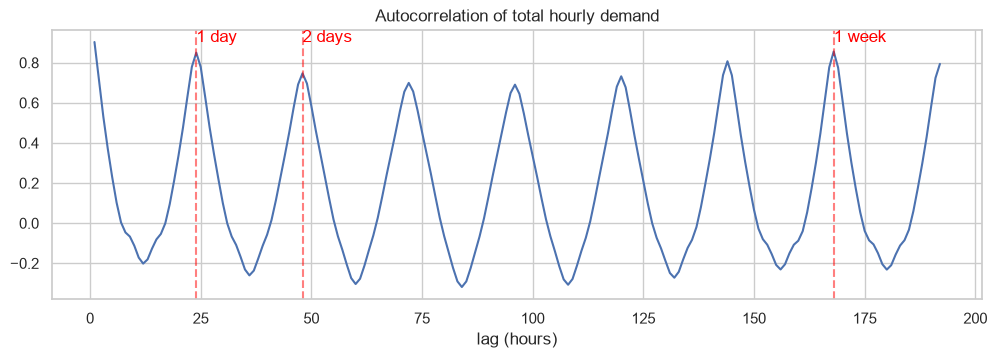

{24: 0.85, 48: 0.747, 168: 0.856}


In [3]:
total = df[df.ts >= df.ts.max() - pd.Timedelta(days=365)].groupby("ts")[TARGET].sum()
lags = range(1, 24 * 8 + 1)
acf = pd.Series([total.autocorr(l) for l in lags], index=lags)
plt.figure(figsize=(12, 3.5))
acf.plot()
for l, label in [(24, "1 day"), (48, "2 days"), (168, "1 week")]:
    plt.axvline(l, color="red", ls="--", alpha=.5); plt.text(l, acf.max(), label, color="red")
plt.title("Autocorrelation of total hourly demand"); plt.xlabel("lag (hours)"); plt.show()
print(acf[[24, 48, 168]].round(3).to_dict())

**Reading the plot (rewrite in your own words):** the strongest spikes are at 24 and 168 hours: today looks like yesterday, and even more like the same weekday last week. That is why *same hour last week* is the baseline to beat.

## 4. Baselines 1-3: no learning, just lookups
All three are scored the same way: **validation** and **test**. "Last year's average" for a target period is built from the 12 months immediately before it, so for validation it uses the last 12 months of train, and for the test year it uses the validation year. We do not use all years, because demand has grown a lot and old years would pull the average down.

In [4]:
results = {}                      # name -> (valid_pred, test_pred)

# 1. global mean of the previous 12 months
prev_for_valid = train[train.ts >= valid_start - pd.DateOffset(years=1)]
results["global_mean"] = (np.full(len(valid), prev_for_valid[TARGET].mean()),
                          np.full(len(test), valid[TARGET].mean()))

# 2. last year's average per station x hour x weekday/weekend
va_pred, _ = lookup_baseline(prev_for_valid, valid)
te_pred, lookup = lookup_baseline(valid, test)
results["baseline_last_year"] = (va_pred, te_pred)

# 3. seasonal naive: the same hour one week earlier (first week of a station: fall back to the mean)
sn = seasonal_naive(df)
results["baseline_seasonal_naive"] = (sn.loc[valid.index].fillna(valid[TARGET].mean()).to_numpy(),
                                      sn.loc[test.index].fillna(test[TARGET].mean()).to_numpy())
for name, (pv, pt) in results.items():
    print(f"{name:25s} valid MAE={regression_metrics(valid[TARGET], pv)['MAE']:.3f}   test MAE={regression_metrics(test[TARGET], pt)['MAE']:.3f}")

global_mean               valid MAE=8.359   test MAE=8.935
baseline_last_year        valid MAE=5.076   test MAE=5.447
baseline_seasonal_naive   valid MAE=4.816   test MAE=5.205


## 5. Baseline 4: linear regression (Ridge)
The simplest model that *learns*. Calendar features are one-hot encoded (a station is not "worth" more than another because its number is higher; one-hot encoding is the fix from the Data augmentation chapter), hour is cyclic (sin/cos), and numeric columns are scaled, because linear models are sensitive to scale (trees are not). Ridge is linear regression with a small penalty on large coefficients.

A linear model has ~130 parameters, so it does not need 10M rows: we train it on a random sample of at most 2M rows of the training period, which keeps memory small.

**What it cannot do:** the rush-hour peak exists on weekdays and not on weekends, which is an *interaction* between features. A linear model adds effects up and cannot represent that. Trees can. This is the bias side of the bias-variance trade-off.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CAT = ["station", "dayofweek", "month"]
NUM = ["hour_sin", "hour_cos", "is_weekend", "is_holiday", "year"]

def make_linear():
    prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
                              ("num", StandardScaler(), NUM)])
    return Pipeline([("prep", prep), ("ridge", Ridge(alpha=1.0))])

def linear_input(d):
    X = d[CAT + NUM].copy()
    X["station"] = X["station"].astype(str)
    return X

def fit_linear(rows):
    rows = rows.sample(min(2_000_000, len(rows)), random_state=42)
    return make_linear().fit(linear_input(rows), rows[TARGET])

lin = fit_linear(train)                                     # trained on train  -> validation score
lin_final = fit_linear(pd.concat([train, valid]))           # trained on train+valid -> test score
results["linear_ridge"] = (np.clip(lin.predict(linear_input(valid)), 0, None),
                           np.clip(lin_final.predict(linear_input(test)), 0, None))
print("done")

done


## 6. Scores
Validation decides the ranking; test is reported next to it.

In [6]:
notes = {"global_mean": "mean of the previous 12 months",
         "baseline_last_year": "station x hour x weekend mean of the previous 12 months",
         "baseline_seasonal_naive": "same station, same hour, one week earlier",
         "linear_ridge": "Ridge on one-hot station/weekday/month + cyclic hour, <=2M training rows"}
for name, (pv, pt) in results.items():
    save_metrics(name, regression_metrics(valid[TARGET], pv), regression_metrics(test[TARGET], pt),
                 where="local", note=notes[name])
load_metrics()[["valid_MAE", "valid_RMSE", "valid_R2", "test_MAE", "test_RMSE", "test_R2"]].round(3)

,valid_MAE,valid_RMSE,valid_R2,test_MAE,test_RMSE,test_R2
baseline_seasonal_naive,4.816103,7.624048,0.551406,5.205211,8.409907,0.498655
baseline_last_year,5.075872,7.867899,0.522251,5.447443,8.278868,0.514157
linear_ridge,5.937776,9.137574,0.355617,6.322705,9.51637,0.358057
global_mean,8.359283,11.477536,-0.016669,8.935258,11.878421,-0.000165


**Metrics:** *MAE* is the average absolute error in trips per hour ("on average we are X trips off"). *RMSE* punishes big errors more, so it reacts to missed rush-hour peaks. *R2* is the share of variance explained (0 = as good as predicting the mean). Lower is better for MAE and RMSE.

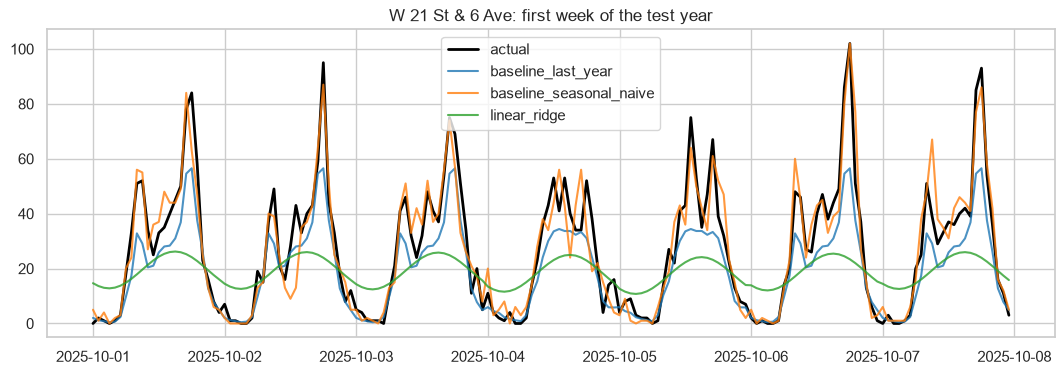

In [7]:
# the quick first model for the API: last year's lookup, plus the ridge model
import joblib
Path("models").mkdir(exist_ok=True)
joblib.dump({"lookup": lookup, "keys": ["station", "hour", "is_weekend"],
             "fallback": float(valid[TARGET].mean())}, "models/baseline.pkl")

res = test.assign(**{k: v[1] for k, v in results.items()})
st = res.groupby("station", observed=True)[TARGET].sum().idxmax()
wk = res[res.station == st].iloc[: 24 * 7]
plt.figure(figsize=(13, 4))
plt.plot(wk.ts, wk[TARGET], label="actual", lw=2, color="black")
for k, c in [("baseline_last_year", "tab:blue"), ("baseline_seasonal_naive", "tab:orange"), ("linear_ridge", "tab:green")]:
    plt.plot(wk.ts, wk[k], label=k, color=c, alpha=.8)
plt.title(f"{st}: first week of the test year"); plt.legend(); plt.show()

**Conclusions (rewrite in your own words after running):**
- Which baseline is hardest to beat on validation? Is seasonal naive better than last year's average, and why (hint: it knows about the last week, including weather and recent growth)?
- By how much does the linear model beat or lose against the lookups? What does it miss in the plot (peak height on weekdays vs weekends)?
- Seasonal naive needs the real demand of last week. A website visitor asking about next month cannot supply it, so this baseline is a *reference*, not something we can deploy for far-future dates.

These are the numbers every ML model in 05 and later has to beat.

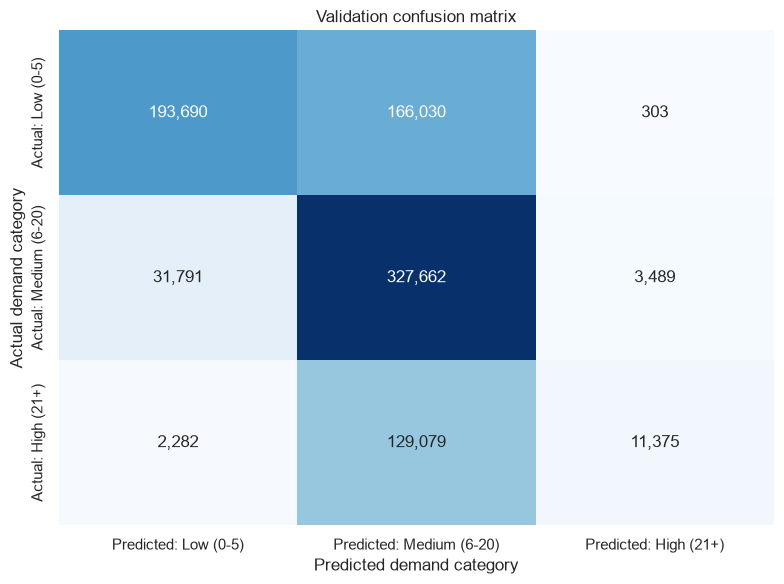

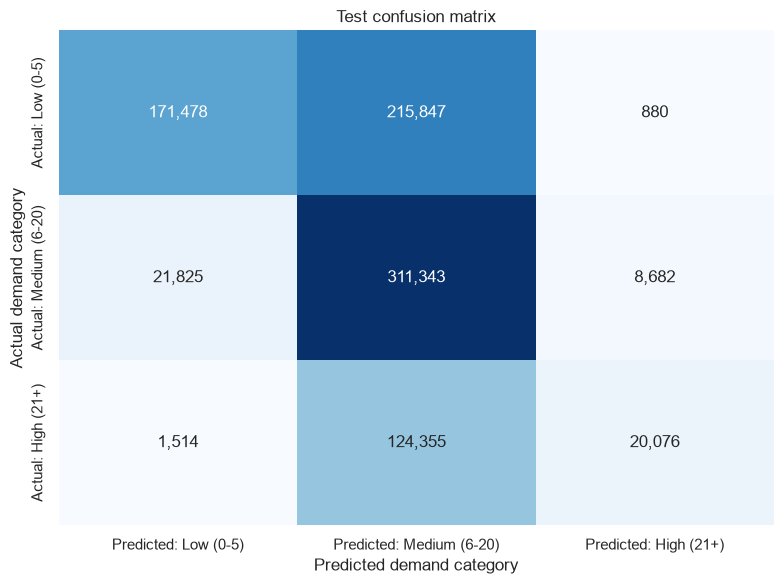

Validation weighted F1 score: 0.577
Test weighted F1 score: 0.543


0.5433928127631059

In [10]:
from sklearn.metrics import confusion_matrix, f1_score

# A confusion matrix needs classes, so convert numeric trip counts to demand bands.
# Change these cutoffs if your project defines different demand levels.
DEMAND_BINS = [-np.inf, 5, 20, np.inf]
DEMAND_LABELS = ["Low (0-5)", "Medium (6-20)", "High (21+)"]


def demand_class(values):
    return pd.cut(np.asarray(values), bins=DEMAND_BINS, labels=DEMAND_LABELS, include_lowest=True)


def show_confusion_matrix(actual, predicted, title):
    actual_class = demand_class(actual)
    predicted_class = demand_class(np.clip(predicted, 0, None))
    matrix = confusion_matrix(actual_class, predicted_class, labels=DEMAND_LABELS)
    matrix_df = pd.DataFrame(matrix, index=[f"Actual: {label}" for label in DEMAND_LABELS], columns=[f"Predicted: {label}" for label in DEMAND_LABELS])
    plt.figure(figsize=(8, 6))
    sns.heatmap(matrix_df, annot=True, fmt=",d", cmap="Blues", cbar=False)
    plt.title(title)
    plt.ylabel("Actual demand category")
    plt.xlabel("Predicted demand category")
    plt.tight_layout()
    plt.show()
    return matrix_df


def show_f1_score(actual, predicted, title):
    actual_class = demand_class(actual)
    predicted_class = demand_class(np.clip(predicted, 0, None))
    score = f1_score(actual_class, predicted_class, labels=DEMAND_LABELS, average="weighted", zero_division=0)
    print(f"{title} weighted F1 score: {score:.3f}")
    return score


show_confusion_matrix(valid[TARGET], validation_predictions, "Validation confusion matrix")
show_confusion_matrix(test[TARGET], test_predictions, "Test confusion matrix")
show_f1_score(valid[TARGET], validation_predictions, "Validation")
show_f1_score(test[TARGET], test_predictions, "Test")
